# Bases: teoria, força e pares conjugados
### Funções inorgânicas — bases

**Objetivo:** Definir base por Arrhenius e Brønsted–Lowry, usar $K_b$ e a relação $K_a K_b = K_w$ para comparar bases fortes e fracas.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

**Base**, segundo Arrhenius, é toda substância que em água libera o ânion hidroxila $\mathrm{OH^-}$. Segundo Brønsted–Lowry, é toda espécie **receptora de próton** — definição mais ampla, que inclui a amônia, que não tem $\mathrm{OH^-}$ na fórmula:

$$
\boxed{\mathrm{B + H_2O \rightleftharpoons BH^+ + OH^-}}
$$

A constante de basicidade é

$$
K_b = \frac{[\mathrm{BH^+}][\mathrm{OH^-}]}{[\mathrm{B}]}, \qquad \mathrm{p}K_b = -\log_{10} K_b
$$

e, para um par conjugado, vale a relação mais útil do assunto:

$$
\boxed{K_a \cdot K_b = K_w = 1{,}0\times10^{-14}}
\qquad\Rightarrow\qquad
\mathrm{p}K_a + \mathrm{p}K_b = 14
$$

Ou seja: **base forte ↔ ácido conjugado fraco**. O $\mathrm{OH^-}$ é a base forte máxima em água; sua base conjugada é a água, que é um ácido fraquíssimo.

## 2. Exemplo resolvido passo a passo

Comparar duas bases de mesma concentração, $c = 0{,}100\ \mathrm{mol/L}$: hidróxido de sódio (forte) e amônia (fraca, $K_b = 1{,}8\times10^{-5}$).

**Passo 1 — NaOH, base forte (dissociação total).**

$$
[\mathrm{OH^-}] = c = 0{,}100\ \mathrm{mol/L}
\quad\Rightarrow\quad
\mathrm{pOH} = 1{,}00
\quad\Rightarrow\quad
\mathrm{pH} = 14 - 1{,}00 = \boxed{13{,}00}
$$

**Passo 2 — amônia, base fraca.**

$$
[\mathrm{OH^-}] \approx \sqrt{K_b\,c} = \sqrt{1{,}8\times10^{-5}\cdot 0{,}100} = 1{,}34\times10^{-3}\ \mathrm{mol/L}
$$

$$
\mathrm{pOH} = 2{,}87 \quad\Rightarrow\quad \mathrm{pH} = 14 - 2{,}87 = \boxed{11{,}13}
$$

**Passo 3 — conferindo pelo par conjugado.**

O ácido conjugado da amônia é o $\mathrm{NH_4^+}$, com

$$
K_a = \frac{K_w}{K_b} = \frac{1{,}0\times10^{-14}}{1{,}8\times10^{-5}} = 5{,}6\times10^{-10}
\quad\Rightarrow\quad
\mathrm{p}K_a = 9{,}25
$$

A conta bate: a base é fraca justamente porque seu ácido conjugado também é fraco (mas não tanto quanto a água, $\mathrm{p}K_a = 15{,}7$).

## 3. Conferindo o cálculo com Python

In [2]:
# @title Força de bases: pOH, pH e Ka do par conjugado
import math

KW = 1.0e-14
C = 0.100
KB_NH3 = 1.8e-5

def ph_base_forte(concentracao):
    """Base forte monoprótica: [OH-] = c."""
    return 14 + math.log10(concentracao)

def ph_base_fraca(concentracao, kb):
    """Base fraca: [OH-] ~ raiz(Kb*c); devolve (pH, [OH-])."""
    oh = math.sqrt(kb * concentracao)
    return 14 + math.log10(oh), oh

pH_forte = ph_base_forte(C)
pH_fraca, oh_fraca = ph_base_fraca(C, KB_NH3)
ka_conjugado = KW / KB_NH3

print(f"Concentração:            {C:.3f} mol/L")
print(f"pH do NaOH (forte):      {pH_forte:.2f}")
print(f"pH da NH3 (fraca):       {pH_fraca:.2f}")
print(f"[OH-] da amônia:         {oh_fraca:.2e} mol/L")
print(f"Kb da amônia:            {KB_NH3:.1e}  -> pKb {-math.log10(KB_NH3):.2f}")
print(f"Ka do NH4+ (conjugado):  {ka_conjugado:.2e}  -> pKa {-math.log10(ka_conjugado):.2f}")
print(f"Ka * Kb = Kw?            {ka_conjugado * KB_NH3:.1e}")

Concentração:            0.100 mol/L
pH do NaOH (forte):      13.00
pH da NH3 (fraca):       11.13
[OH-] da amônia:         1.34e-03 mol/L
Kb da amônia:            1.8e-05  -> pKb 4.74
Ka do NH4+ (conjugado):  5.56e-10  -> pKa 9.26
Ka * Kb = Kw?            1.0e-14


## 4. Visualização

### 4.1 Amônia em 3D — arraste para girar

A amônia $\mathrm{NH_3}$ tem geometria **piramidal trigonal** (o par de elétrons livres ocupa a quarta posição). É esse par livre que recebe o próton, formando o $\mathrm{NH_4^+}$ tetraédrico.

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("N")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 O íon amônio em 3D

Depois de receber o próton, o nitrogênio fica com quatro ligações iguais e a geometria vira **tetraédrica** (109,5°). Compare com a amônia: é a "pegada" visual de uma reação ácido-base.

In [4]:
molecula_3d("[NH4+]")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 O íon hidróxido em 3D

O $\mathrm{OH^-}$ é diatômico e carregado. Em água ele não fica isolado por muito tempo: forma pontes de hidrogênio com as moléculas vizinhas (é o que faz a base "viajar" rápido na solução).

In [5]:
molecula_3d("[OH-]")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.4 Os três em 2D, com os risquinhos

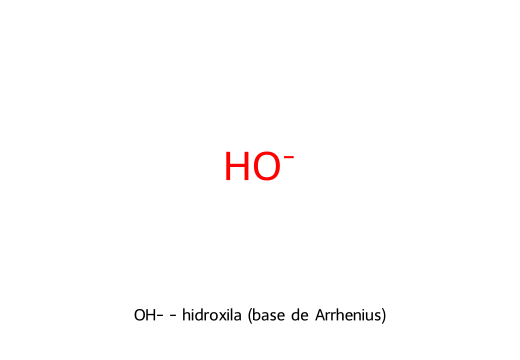

In [6]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("N", legenda="NH3 - amonia (base de Bronsted)")
estrutura_2d("[NH4+]", legenda="NH4+ - acido conjugado")
estrutura_2d("[OH-]", legenda="OH- - hidroxila (base de Arrhenius)")

### 4.5 pH × concentração: base forte contra fraca

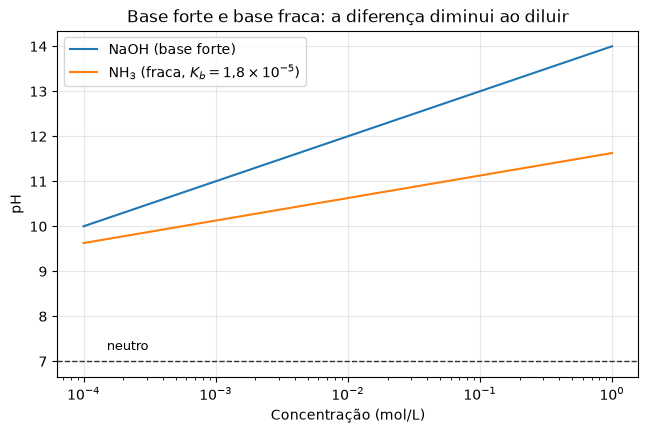

In [7]:
# @title Curvas de pH de bases
import numpy as np
import matplotlib.pyplot as plt

concentracoes = np.logspace(-4, 0, 80)
plt.figure(figsize=(7.5, 4.5))
plt.plot(concentracoes, 14 + np.log10(concentracoes), label="NaOH (base forte)")
plt.plot(concentracoes, 14 + np.log10(np.sqrt(KB_NH3 * concentracoes)),
         label="NH$_3$ (fraca, $K_b=1{,}8\\times10^{-5}$)")
plt.axhline(7, color="#333", linestyle="--", linewidth=1)
plt.text(1.5e-4, 7.25, "neutro", fontsize=9)
plt.xscale("log")
plt.xlabel("Concentração (mol/L)")
plt.ylabel("pH")
plt.title("Base forte e base fraca: a diferença diminui ao diluir")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 4.6 Pares conjugados: quem é forte, quem é fraco

In [8]:
# @title Ka x Kb dos pares conjugados
pares = [
    ("OH-/H2O", 15.7, -1.7),
    ("NH3/NH4+", 9.25, 4.75),
    ("CH3NH2/CH3NH3+", 10.6, 3.4),
    ("HCO3-/H2CO3", 6.35, 7.65),
    ("CH3COO-/CH3COOH", 4.76, 9.24),
]
print(f"{'par conjugado':20s} {'pKa(ácido)':>11s} {'pKb(base)':>10s} {'soma':>6s}")
for nome, pka_par, pkb_par in pares:
    print(f"{nome:20s} {pka_par:11.2f} {pkb_par:10.2f} {pka_par + pkb_par:6.2f}")

par conjugado         pKa(ácido)  pKb(base)   soma
OH-/H2O                    15.70      -1.70  14.00
NH3/NH4+                    9.25       4.75  14.00
CH3NH2/CH3NH3+             10.60       3.40  14.00
HCO3-/H2CO3                 6.35       7.65  14.00
CH3COO-/CH3COOH             4.76       9.24  14.00


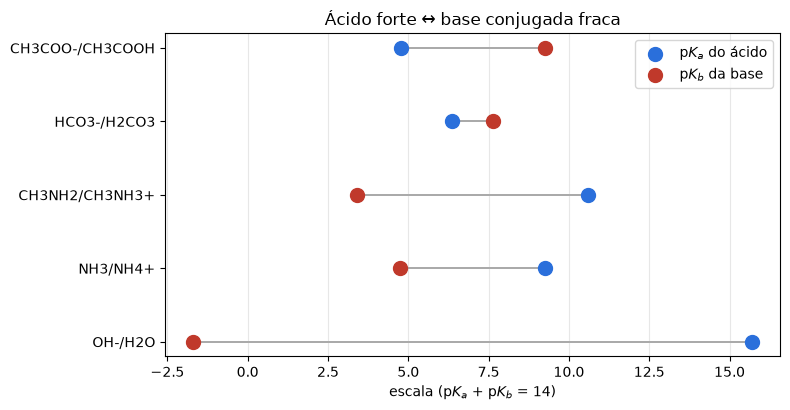

In [9]:
# @title Gráfico dos pares
nomes = [nome for nome, _, _ in pares]
pka = [a for _, a, _ in pares]
pkb = [b for _, _, b in pares]

plt.figure(figsize=(8, 4.2))
plt.scatter(pka, range(len(pares)), s=100, color="#2a6fdb", label="p$K_a$ do ácido", zorder=3)
plt.scatter(pkb, range(len(pares)), s=100, color="#c0392b", label="p$K_b$ da base", zorder=3)
for i, (a, b) in enumerate(zip(pka, pkb)):
    plt.plot([a, b], [i, i], color="#999", linewidth=1.2, zorder=1)
plt.yticks(range(len(pares)), nomes)
plt.xlabel("escala (p$K_a$ + p$K_b$ = 14)")
plt.title("Ácido forte ↔ base conjugada fraca")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- A base forte está 100% dissociada: o pH depende só da concentração. A fraca ioniza 1,3% e o pH fica quase 2 unidades menor (mais próximo do neutro).
- $K_a K_b = K_w$ permite trocar de escala: achou $\mathrm{p}K_a$ do ácido conjugado, já sabe o $\mathrm{p}K_b$ da base.
- No 3D, amônia (piramidal) → amônio (tetraédrico) é a mudança de geometria que acompanha a transferência de próton.
- Ordem de basicidade em água: $\mathrm{OH^-} \gg$ aminas > amônia > bases com ânion de ácido fraco (acetato, carbonato) > água.

## 6. Exercício de fixação

A metilamina ($\mathrm{CH_3NH_2}$) tem $K_b = 4{,}4\times10^{-4}$. Calcule o pH de uma solução $0{,}020\ \mathrm{mol/L}$ e o $\mathrm{p}K_a$ do $\mathrm{CH_3NH_3^+}$.

In [10]:
# @title Exercício
KB_EX, C_EX = 4.4e-4, 0.020
pH_ex, oh_ex = ph_base_fraca(C_EX, KB_EX)
print(f"[OH-] = {oh_ex:.2e} mol/L")
print(f"pOH   = {-math.log10(oh_ex):.2f}")
print(f"pH    = {pH_ex:.2f}")
print(f"pKb   = {-math.log10(KB_EX):.2f}")
print(f"pKa(conjugado) = {14 + math.log10(KB_EX):.2f}")

[OH-] = 2.97e-03 mol/L
pOH   = 2.53
pH    = 11.47
pKb   = 3.36
pKa(conjugado) = 10.64


## 7. Resumo

- Base de Arrhenius libera $\mathrm{OH^-}$; de Brønsted–Lowry **recebe próton**.
- $K_b$ mede a força; maior $K_b$ (menor $\mathrm{p}K_b$) = base mais forte.
- $K_a K_b = K_w$: par conjugado tem forças invertidas.
- Base forte: $[\mathrm{OH^-}] = c$. Base fraca: $[\mathrm{OH^-}] \approx \sqrt{K_b c}$.
- $\mathrm{pH} = 14 - \mathrm{pOH}$ a 25 °C.

## Referências

- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- FELTRE, R. *Química Geral*. Moderna.
- IUPAC. *Compendium of Chemical Terminology* (Gold Book).